# 3 · Tokens, embeddings, and representations

**Question.** How does text become something a numerical model can use?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/03-tokens-embeddings.ipynb)

**Python support:** Review Appendix A.1–A.4 for indexing, loops and array axes. Predict the shape of every intermediate array before running it. Use **Show all code** while working.


A model receives numbers, not the meaning of a sentence. Tokenization defines the discrete observations; an embedding maps those observations into vectors. We will construct both operations explicitly, fit a small distributional representation, and test what it fails to preserve. The statistical analogues are the construction of a design matrix and the estimation of a feature map.

**Prerequisites:** Chapters 1–2 and singular value decomposition (SVD). **Outcomes:** distinguish words from tokens; handle unknown inputs; interpret an embedding lookup; explain why proximity is task-dependent. The corpus below consists of short, course-authored sentences, so no download is necessary.

## Pipeline and framework

![Learn a tokenizer, vocabulary and embedding table on training text; apply these fitted objects to new text before contextual modeling. Remember: learn the codebook once, reuse the same codebook.](https://chikuang.github.io/teaching/genai/_static/diagrams/03-representation.png)

A representation pipeline contains **fitted preprocessing objects**, not just neural weights. The tokenizer defines what the IDs mean; the embedding matrix maps those IDs to vectors. Changing the vocabulary without changing the embedding table can preserve array shapes while silently changing the model's meaning.

| Stage | Output artifact | Main check |
|:--|:--|:--|
| Normalize and tokenize | Rules, merge table, vocabulary, special-token policy | Apply exactly the same rules to training and new text. |
| Encode | An integer sequence and an unknown-token strategy | Every ID indexes the intended row; document how information is lost. |
| Fit embeddings | Co-occurrence statistics and a factorization, or a learned matrix | Estimate from the allowed training corpus and retain the version. |
| Add position and context | Position-aware states, then contextual states | A lookup vector is context independent; an encoder output need not be. |

The small BPE-style merge experiment and the PPMI/SVD experiment below illustrate **different parts** of this framework. They are not a claim that production tokenizers use the exact toy procedure or that transformer embeddings must be trained with SVD. For a new sentence, freeze the chosen preprocessing objects before looking up vectors; do not rebuild a vocabulary separately for every query.

## 3.1 · A vocabulary is an estimated preprocessing object

We first use a word tokenizer that lowercases text and keeps alphabetic runs. This is a teaching choice, not a general text-processing standard: it discards punctuation, numbers, capitalization, and much non-English text.

In [1]:
import re
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

corpus = [
    'probability models describe uncertainty',
    'statistical models estimate probability',
    'data support statistical inference',
    'inference quantifies uncertainty from data',
    'neural networks learn representations',
    'language models learn token representations',
    'attention combines token representations',
    'networks use attention to model language',
]
def tokenize(text):
    return re.findall(r'[a-z]+', text.lower())

vocab = ['<unk>'] + sorted({w for s in corpus for w in tokenize(s)})
to_id = {word: i for i, word in enumerate(vocab)}
def encode(text):
    return [to_id.get(word, 0) for word in tokenize(text)]

print(tokenize('Models: 2 estimates, NOT certainty!'))
print(encode('probability models encounter novelty'))
print([vocab[i] for i in encode('probability models encounter novelty')])

['models', 'estimates', 'not', 'certainty']
[14, 11, 0, 0]
['probability', 'models', '<unk>', '<unk>']


Build the vocabulary from training text and freeze it before evaluation. Mapping unseen words to `<unk>` avoids an indexing error but loses distinctions between them. Character or byte tokenizers reduce this problem at the cost of longer sequences. Subword tokenizers trade vocabulary size against sequence length. A token may be part of a word, punctuation, or a byte sequence; counting tokens is not counting words.

### Tokenization defines the sample space

Write a fitted tokenizer as $\tau:\mathcal S\to\mathcal V^*$, where $\mathcal S$ is the set of input strings, $\mathcal V=\{0,\ldots,V-1\}$ is the vocabulary, and $\mathcal V^*$ contains finite token sequences. For a string $s$,

$$
\tau(s)=(x_1,\ldots,x_{T(s)}),\qquad
X_{t,:}=E_{x_t,:},\quad E\in\mathbb R^{V\times d}.
$$

$T(s)$ depends on the tokenizer. Our normalization makes $\tau$ many-to-one: two distinct strings can have identical IDs. A model operating only on those IDs cannot distinguish them. Changing $\tau$ changes the events being scored, which is why per-token losses from different tokenizers need not be directly comparable.

## 3.2 · A miniature byte-pair-style merge experiment

Byte-pair encoding repeatedly merges frequent adjacent units. Real implementations include normalization, boundary conventions, special tokens, and efficient encoders. This word-internal character experiment isolates the merge idea; it is **not** a byte-level production tokenizer.

In [2]:
word_counts = Counter({'learn': 6, 'learning': 5, 'learned': 3,
                       'model': 5, 'models': 4})
segments = {word: list(word) + ['</w>'] for word in word_counts}
merges = []
for _ in range(6):
    pair_counts = Counter()
    for word, parts in segments.items():
        for pair in zip(parts, parts[1:]):
            pair_counts[pair] += word_counts[word]
    pair = max(sorted(pair_counts), key=pair_counts.get)
    merges.append(pair)
    for word, parts in list(segments.items()):
        result, i = [], 0
        while i < len(parts):
            if i + 1 < len(parts) and tuple(parts[i:i+2]) == pair:
                result.append(parts[i] + parts[i+1])
                i += 2
            else:
                result.append(parts[i])
                i += 1
        segments[word] = result
print('Merge order:', merges)
print('Final segments:', segments)

Merge order: [('a', 'r'), ('ar', 'n'), ('e', 'arn'), ('l', 'earn'), ('d', 'e'), ('de', 'l')]
Final segments: {'learn': ['learn', '</w>'], 'learning': ['learn', 'i', 'n', 'g', '</w>'], 'learned': ['learn', 'e', 'd', '</w>'], 'model': ['m', 'o', 'del', '</w>'], 'models': ['m', 'o', 'del', 's', '</w>']}


The frequencies weight the merge decisions. A tokenizer trained on one domain can segment another domain inefficiently. Once learned, the merge order is part of the model artifact and must be saved. Do not fit a fresh tokenizer independently for each evaluation sample: token probabilities would then refer to different events.

## 3.3 · One-hot encoding and lookup are the same linear operation

For vocabulary size $V$, token $j$ has one-hot row vector $e_j^\top$. An embedding matrix $E\in\mathbb R^{V\times d}$ maps it to $e_j^\top E=E_{j,:}$. Lookup avoids allocating a mostly zero vector. A sequence of length $T$ becomes a $T\times d$ matrix; a batch adds a leading dimension.

In [3]:
rng = np.random.default_rng(3)
E = rng.normal(scale=0.2, size=(len(vocab), 4))
ids = np.array(encode('statistical models estimate probability'))
one_hot = np.eye(len(vocab))[ids]
assert np.allclose(one_hot @ E, E[ids])
print('IDs:', ids.shape, 'one-hot:', one_hot.shape, 'lookup:', E[ids].shape)

IDs: (4,) one-hot: (4, 23) lookup: (4, 4)


These randomly initialized vectors have no learned semantic interpretation. In a neural language model, the prediction loss supplies gradients for the rows used in training. Similar contexts can encourage similar predictive representations, but the learned geometry also reflects corpus composition and the training objective.

> **Example 3.1 · A token ID selects a row**
>
> **Setup.** Let IDs 0, 1, and 2 mean `data`, `model`, and `learn`. Their embedding rows are $(1,0)$, $(0,2)$, and $(1,1)$, so $E$ has shape $3\times2$.
>
> **Work it through.** The sequence `learn data` becomes IDs `[2, 0]`. Lookup returns rows $(1,1)$ and $(1,0)$, with shape $2\times2$. Multiplying the corresponding one-hot rows $(0,0,1)$ and $(1,0,0)$ by $E$ produces exactly the same result. ID 2 does not mean twice as much as ID 1; the integers are row addresses.
>
> **What this shows.** The vocabulary mapping and embedding matrix form one fitted object. If a rebuilt vocabulary swaps the IDs of `data` and `learn` without reordering $E$, the code still runs but silently assigns the wrong vectors to the words.

## 3.4 · Learn a small representation from co-occurrence

Let $C_{ij}$ count how often token $j$ occurs within a window of token $i$. Positive pointwise mutual information compares joint occurrence with independence:

$$
M_{ij}=\max\left\{0,\log\frac{C_{ij}N}{C_{i+}C_{+j}}\right\},
\qquad N=\sum_{ij}C_{ij}.
$$

Zero-count cells receive zero in this illustrative PPMI matrix. Rare co-occurrences can have large values, so smoothing and frequency thresholds matter in larger applications. We factor the PPMI matrix from Equation [(3.1)](https://chikuang.github.io/teaching/genai/chapters/03-tokens-embeddings.html#equation-eq-ppmi) as $M\approx U_dS_dV_d^\top$ and use $U_dS_d^{1/2}$ as an embedding. This is a distributional matrix-factorization example, not a pretrained language model.

Neighbors of probability: [('estimate', 0.991), ('models', 0.983), ('describe', 0.976), ('statistical', 0.546)]
Neighbors of attention: [('use', 0.993), ('to', 0.87), ('model', 0.841), ('language', 0.832)]


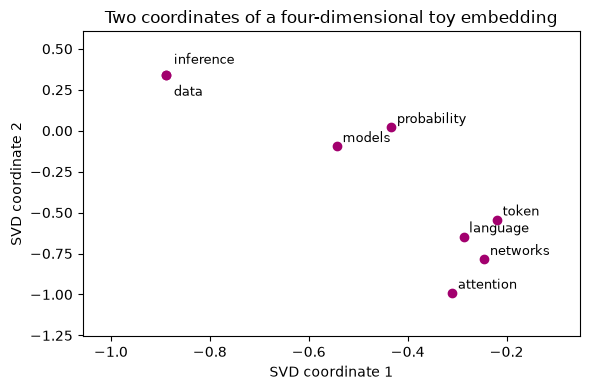

In [4]:
C = np.zeros((len(vocab), len(vocab)))
for sentence in corpus:
    ids = encode(sentence)
    for i, token in enumerate(ids):
        for j in range(max(0, i-2), min(len(ids), i+3)):
            if i != j:
                C[token, ids[j]] += 1
expected = C.sum(1, keepdims=True) @ C.sum(0, keepdims=True)
ratio = np.divide(C * C.sum(), expected,
                  out=np.ones_like(C), where=(C > 0) & (expected > 0))
M = np.maximum(np.log(ratio), 0)
U, s, Vt = np.linalg.svd(M, full_matrices=False)
emb = U[:, :4] * np.sqrt(s[:4])
unit = emb / np.maximum(np.linalg.norm(emb, axis=1, keepdims=True), 1e-12)

def neighbors(word, k=4):
    scores = unit @ unit[to_id[word]]
    order = np.argsort(-scores)
    return [(vocab[i], round(float(scores[i]), 3))
            for i in order if i != to_id[word] and i != 0][:k]

print('Neighbors of probability:', neighbors('probability'))
print('Neighbors of attention:', neighbors('attention'))
fig, ax = plt.subplots(figsize=(6, 4))
for word in ['probability', 'models', 'inference', 'data',
             'attention', 'token', 'language', 'networks']:
    i = to_id[word]
    ax.scatter(*emb[i, :2], color='#a2006e')
    offset = {'data': (6, -15), 'inference': (6, 8)}.get(word, (4, 3))
    ax.annotate(word, emb[i, :2], xytext=offset, textcoords='offset points', fontsize=9)
ax.margins(x=0.25, y=0.2)
ax.set(xlabel='SVD coordinate 1', ylabel='SVD coordinate 2',
       title='Two coordinates of a four-dimensional toy embedding')
plt.tight_layout()
plt.show()

Inspect the neighbors instead of assuming they are sensible. Eight sentences are too few to establish robust language structure. Words absent from similar contexts may appear dissimilar despite related meanings. The plot discards two coordinates and can further distort distances. Neither the plot nor cosine similarity establishes a causal relationship.

### What the factorization and similarity measure optimize

For the full SVD $M=U\Sigma V^\top$, retaining the $d$ largest singular values gives a solution to

$$
M_d\in\operatorname*{arg\min}_{\operatorname{rank}(A)\le d}
\|M-A\|_F^2,\qquad M_d=U_d\Sigma_dV_d^\top.
$$

The Frobenius norm sums squared matrix entries. Equation [(3.2)](https://chikuang.github.io/teaching/genai/chapters/03-tokens-embeddings.html#equation-eq-low-rank-embedding) is a low-rank approximation to **PPMI**, not maximum likelihood for a language model. The row embedding $E=U_d\Sigma_d^{1/2}$ and context embedding $F=V_d\Sigma_d^{1/2}$ satisfy $EF^\top=M_d$; in general $EE^\top\ne M_d$.

For two nonzero row vectors $a,b\in\mathbb R^d$, the neighbor score is

$$
\operatorname{cos}(a,b)=\frac{ab^\top}{\sqrt{aa^\top}\sqrt{bb^\top}}\in[-1,1].
$$

Unit-normalizing the vectors in Equation [(3.3)](https://chikuang.github.io/teaching/genai/chapters/03-tokens-embeddings.html#equation-eq-cosine) turns cosine into a dot product. The lexical RAG retriever in Chapter 10 uses this same similarity in Equation [(10.3)](https://chikuang.github.io/teaching/genai/chapters/10-rag.html#equation-eq-tfidf). A zero vector has no mathematically defined cosine; the code protects its normalization numerically, but the resulting zero row contains no directional information. Neighbors of such a row should not be interpreted as semantic evidence.

## 3.5 · Identifiability and the loss of order

For an orthogonal matrix $R$, $(ER)(ER)^\top=EE^\top$. Rotating all vectors preserves dot products, norms, and cosine similarities. Individual axes therefore need not correspond to interpretable concepts.

In [5]:
R, _ = np.linalg.qr(rng.normal(size=(4, 4)))
assert np.allclose(emb @ emb.T, (emb @ R) @ (emb @ R).T)
a = tokenize('data support models')
b = tokenize('models support data')
print('Same bag of words:', Counter(a) == Counter(b))
print('Same ordered sequence:', a == b)

Same bag of words: True
Same ordered sequence: False


A mean of static word embeddings also ignores order: permuting the tokens does not change the mean. The two example sentences have the same word counts but reverse the grammatical roles. Negation can cause an even more serious mismatch between lexical similarity and a task's answer.

> **Example 3.2 · Similarity can survive a change of coordinates**
>
> **Setup.** Three word vectors are $a=(1,0)$, $b=(2,0)$, and $c=(0,1)$.
>
> **Work it through.** Equation [(3.3)](https://chikuang.github.io/teaching/genai/chapters/03-tokens-embeddings.html#equation-eq-cosine) gives $\cos(a,b)=1$ and $\cos(a,c)=0$, although $b$ is twice as long as $a$. Rotate every vector by 90 degrees: they become $(0,1)$, $(0,2)$, and $(-1,0)$. The two cosine values remain 1 and 0. Also, averaging the vectors for `data model` gives the same result as averaging `model data`.
>
> **What this shows.** Relative geometry can carry information even when individual coordinate meanings are not identifiable. Cosine is directional similarity, not a probability of equivalence. Averaging also erases order, which motivates positional and contextual representations in the next section.

## 3.6 · Positions and contextual representations

A static lookup gives the same vector to every occurrence of a token. A contextual representation is a function of its surrounding sequence, for example $h_t=f_\theta(x_{1:T},t)$. Adding a positional vector supplies order information before attention. One possible fixed encoding uses sine and cosine functions at different frequencies.

In [6]:
T, d = 5, 4
positions = np.arange(T)[:, None]
frequencies = 10000 ** (-np.arange(0, d, 2) / d)
P = np.zeros((T, d))
P[:, 0::2] = np.sin(positions * frequencies)
P[:, 1::2] = np.cos(positions * frequencies)
print(np.round(P, 3))
assert not np.allclose(P[0], P[1])

[[ 0.     1.     0.     1.   ]
 [ 0.841  0.54   0.01   1.   ]
 [ 0.909 -0.416  0.02   1.   ]
 [ 0.141 -0.99   0.03   1.   ]
 [-0.757 -0.654  0.04   0.999]]


For even width $d$ and position $t=0,1,\ldots$, the fixed positional code used here is

$$
P_{t,2j}=\sin\left(\frac{t}{10000^{2j/d}}\right),\qquad
P_{t,2j+1}=\cos\left(\frac{t}{10000^{2j/d}}\right),
\quad j=0,\ldots,d/2-1.
$$

The input state is $X_{t,:}=E_{x_t,:}+P_{t,:}$. The sum preserves width $d$ while making position available; subsequent attention creates context dependence. Our later decoder uses learned position vectors instead of these fixed ones.

Position features do not themselves create understanding. They allow a model to distinguish order when the prediction objective rewards doing so. Learned absolute positions and relative-position mechanisms are other options; each has implications for generalizing to lengths not seen in training. Padding positions also need an explicit mask so they do not become evidence.


### Coding and experiment practice · Refit a representation and align its vocabulary

**1. Predict before running.** If deleting a sentence removes a word, why can row number 5 represent different words in two fitted matrices?

**2. Implement and check.** Complete the entire workflow: rebuild vocabulary, count co-occurrences, compute PPMI, refit SVD, intersect vocabularies, and rank neighbors. The reference returns a dictionary from word to vector so row numbers cannot silently misalign. Try your own implementation before expanding the reference code below. Replace the reference function body with your version and rerun the acceptance checks in a fresh kernel.

In [7]:
def fit_representation(texts, dimension=4):
    vocabulary = sorted({word for text in texts for word in tokenize(text)})
    position = {word: i for i, word in enumerate(vocabulary)}
    counts = np.zeros((len(vocabulary), len(vocabulary)))
    for text in texts:
        ids = [position[word] for word in tokenize(text)]
        for i, word_id in enumerate(ids):
            for j in range(max(0, i-2), min(len(ids), i+3)):
                if i != j:
                    counts[word_id, ids[j]] += 1
    expected = counts.sum(1, keepdims=True) @ counts.sum(0, keepdims=True)
    ratios = np.divide(counts * counts.sum(), expected,
                       out=np.ones_like(counts), where=(counts > 0) & (expected > 0))
    ppmi = np.maximum(np.log(ratios), 0)
    left, singular, _ = np.linalg.svd(ppmi, full_matrices=False)
    vectors = left[:, :dimension] * np.sqrt(singular[:dimension])
    return dict(zip(vocabulary, vectors))

Read the fit in four stages. `position` maps words to matrix rows. The nested loops count neighbors within a two-position window. `np.divide(..., where=...)` avoids division by zero; replacing unused ratios by one makes their log zero. SVD then supplies a four-dimensional representation. Finally, `zip` pairs each word with its vector, and `dict` stores those pairs by name. No coordinates from the full-corpus fit are reused in the reduced fit.

The next function accepts the fitted dictionary, query word, and a **shared set of candidate words**. It excludes zero-length vectors because their cosine direction is undefined. A tuple `(-score, word)` sorts highest scores first and breaks ties alphabetically.

In [8]:
def ranked_common_neighbors(fitted, query, common):
    q = fitted[query]
    if np.linalg.norm(q) == 0:
        raise ValueError('Query has no defined cosine direction')
    scores = []
    for word in sorted(common - {query}):
        vector = fitted[word]
        if np.linalg.norm(vector) > 0:
            cosine = float(vector @ q / (np.linalg.norm(vector) * np.linalg.norm(q)))
            scores.append((word, cosine))
    return [word for word, score in sorted(scores, key=lambda pair: (-pair[1], pair[0]))]

def neighbor_overlap(first, second, k):
    if not 1 <= k <= min(len(first), len(second)):
        raise ValueError('Both lists must contain at least k neighbors')
    return len(set(first[:k]) & set(second[:k])) / k

Now assemble the experiment. `corpus[1:]` removes the first sentence. The `&` operator intersects vocabulary sets by word identity. Restrict both rankings to that intersection **before** taking their first four neighbors. Inspect the printed lists as well as the scalar overlap: the scalar hides which words changed.

In [9]:
full_fit = fit_representation(corpus)
reduced_fit = fit_representation(corpus[1:])
common = set(full_fit) & set(reduced_fit)
# Keep only words with a defined direction in both fits.
common = {w for w in common if np.linalg.norm(full_fit[w]) > 0
          and np.linalg.norm(reduced_fit[w]) > 0}
first = ranked_common_neighbors(full_fit, 'models', common)
second = ranked_common_neighbors(reduced_fit, 'models', common)
assert neighbor_overlap(['a', 'b'], ['a', 'b'], 2) == 1
assert neighbor_overlap(['a', 'b'], ['c', 'd'], 2) == 0
print('Removed:', corpus[0], '| common directed vocabulary:', len(common))
print('Neighbors:', first[:4], second[:4], '| overlap:', neighbor_overlap(first, second, 4))

Removed: probability models describe uncertainty | common directed vocabulary: 21
Neighbors: ['estimate', 'probability', 'statistical', 'language'] ['estimate', 'probability', 'learn', 'token'] | overlap: 0.5


The first function repeats fitting; the second compares on a common set; the third summarizes overlap. Alphabetical ordering breaks tied scores reproducibly. We omit the unused unknown-token row in this refitting exercise. A rotated embedding can have identical neighbors, so raw coordinate differences are not the target.

**3. Extend one factor.** Remove each sentence in turn, preselect a query that survives each comparison, and report vocabulary size and overlap. This is sensitivity analysis of eight authored sentences, not a population uncertainty interval.

**Submission and rubric.** Submit the function and its checks, the requested comparison table, and three sentences naming the target, interpreting the result, and limiting the claim. Passing a deterministic fixture verifies the stated calculation; a favorable stochastic result is not required. Retain unexpected results and diagnose them rather than changing seeds until a preferred ranking appears.


## 3.7 · Exercises

1. **Lookup size.** A vocabulary has 10,000 tokens and embedding width 64. How many parameters are in its embedding matrix?
2. **Unknowns.** What information is lost when both “variance” and “entropy” map to `<unk>`?
3. **Rotation.** Prove cosine similarity is unchanged by an orthogonal transformation.
4. **Order.** Construct two sentences with the same bag of words but different meanings.
5. **Sampling variation.** Repeat the SVD after removing one corpus sentence. What should be compared?


<details><summary>Worked solutions — attempt the questions first</summary>

**1.** $640,000$. A batch of 8 sequences of length 20 produces a tensor of shape `(8, 20, 64)`; batch size does not change the parameter count.

**2.** the model receives the same token ID for distinct words. No downstream function of those IDs can recover which word was present without additional information.

**3.** $aRR^\top b^\top=ab^\top$, and the same identity preserves both squared norms. General invertible transformations do not preserve cosine similarity.

**4.** “models explain data” and “data explain models” suffice. A mean-pooling baseline cannot distinguish them; an order-aware model can represent a distinction but must still learn it.

**5.** compare neighbor rankings or pairwise similarities on a common vocabulary. Comparing raw coordinates is misleading because rotations and sign changes are arbitrary. Large changes reveal instability in this tiny corpus.

</details>

## 3.8 · Reading and next step

The [Hugging Face explanation of BPE](https://huggingface.co/learn/llm-course/en/chapter6/5) describes practical tokenizer construction. Our merge experiment and SVD example isolate two separate preprocessing choices. [Chapter 4](https://chikuang.github.io/teaching/genai/chapters/04-attention.html) now makes representations depend on a query and its context.